In [1]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid
from numba import njit, prange
from numba_progress import ProgressBar
from scipy.stats import binned_statistic

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 4.114
dt = 1e-2
eps = 1e-14 # For numerical stability

In [3]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [4]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    x = np.concatenate(([0], x, xh + x[-1]))
    F = np.concatenate(([0], F, Fh))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

# Simulate Trajectories

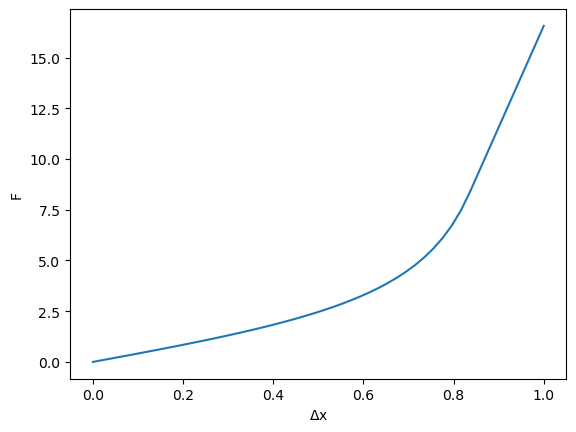

In [5]:
C, _, _ = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")
lut_x = np.linspace(0, 5, 10000)
lut_F = C(lut_x)

# Simulate Trajectories

In [6]:
@njit(parallel=True)
def generate_samples(N, ru, xu, v, lut_x, lut_F, dt, dropout_force=None, length=None, cache_length=10000):
    
    if dropout_force == None:
        dropout_force = -np.inf
        
    lut_size = lut_x.shape[0]
    lut_maxx = lut_x[-1]
    
    force = np.full((cache_length, N), np.nan)
    event = np.zeros(N)

    resets = 0

    for i in prange(N):
        t = 0
        while t < cache_length:
            x = v * t * dt
            if x >= lut_maxx:
                x = lut_maxx
            idx = int(lut_size * x / lut_maxx)
            f = lut_F[min(idx, lut_size-1)]
            force[t, i] = f

            pu = min(dt * ru * np.exp(f*xu/kbT), 1)
            a  = np.random.rand()
            if pu > a:
                if dropout_force > f:
                    force[:t, i] = np.nan
                    resets += 1
                    t = 0
                    continue
                else:
                    event[i] = t-1
                    break
            t += 1

    #print(resets/N)
    return force[:event.max(), :], event

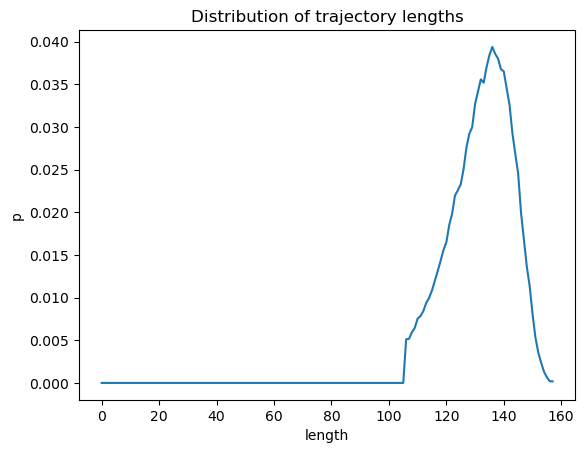

In [43]:
ru_GT = 0.01
xu_GT = 0.8
dropf_GT = 20
forces, event = generate_samples(100000, ru_GT, xu_GT, 1, lut_x, lut_F, dt, dropout_force=dropf_GT, cache_length=1000)

plen = np.histogram(event, bins=np.arange(event.max()))[0]
plen = plen / np.sum(plen)
plt.plot(plen)
plt.title("Distribution of trajectory lengths")
plt.xlabel("length")
plt.ylabel("p")
logplen = np.log(plen + eps)

In [44]:
@njit(parallel=False)
def likelihood(logprior, ru, xu, forces_obs, event, dt, SNR):

    n_obs = forces_obs.shape[1]
    logpost = logprior

    for obs in prange(n_obs):

        #logpost += logplen[int(event[obs])]
        
        for t in range(int(event[obs])):
            F = forces_obs[t, obs]
            p = 1 - dt * ru * np.exp(F * xu / kbT)
            if p > 1:
                p = 1
            if p < 0:
                p = 0
            if t + 1 == event[obs]:
                p = 1 - p
                
                mean = np.mean(forces_obs[:, obs])
                std = np.std(forces_obs[:, obs])
                niveau = (F - mean) / std
                if niveau < SNR:
                    logpost += -np.inf

            logp = np.log(p+eps)
            logpost += logp
    return logpost

# Observations

In [45]:
forces, event = generate_samples(100, ru_GT, xu_GT, 1, lut_x, lut_F, dt, dropout_force=dropf_GT, cache_length=1000)

In [46]:
likelihood(0, ru_GT, xu_GT, forces, event, dt, 1)

-381.1921280008109

# Inference

In [58]:
n_samples = 100
ru = ru_GT
xu = xu_GT
snr = 0

#logplen_res = 100000
#forces__, event__ = generate_samples(logplen_res, ru, xu, 1, lut_x, lut_F, dt, dropout_force=dropf, cache_length=1000)
#plen__ = np.histogram(event__, bins=np.arange(event.max()))[0]
#plen__ = plen__ / np.sum(plen__)
#logplen = np.log(plen__ + eps)

RU = []
XU = []
SNR = []

LOGL = -np.inf # Current chain likelihood

superstep = 1000
for s in tqdm(range(n_samples * superstep)):

    # GIBBS RU
    ru_prop = ru + np.random.randn() * 1e-3
    
    LOGL_prop = likelihood(0, ru_prop, xu, forces, event, dt, snr)
    thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
    a = np.random.rand()
    if a < thresh:
        LOGL = LOGL_prop
        ru = ru_prop

    # GIBBS XU
    xu_prop = xu + np.random.randn() * 1e-2
    
    LOGL_prop = likelihood(0, ru, xu_prop, forces, event, dt, snr)
    thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
    a = np.random.rand()
    if a < thresh:
        LOGL = LOGL_prop
        xu = xu_prop


    # GIBBS CUTOFF FORCE
    if True:
        snr_prop = np.abs(snr + np.random.randn() * 5)
        LOGL_prop = likelihood(0, ru, xu, forces, event, dt, snr_prop)
        thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            LOGL = LOGL_prop
            snr = snr_prop

    if not s % superstep:
        RU.append(ru)
        XU.append(xu)
        SNR.append(snr)

  0%|          | 0/100000 [00:00<?, ?it/s]

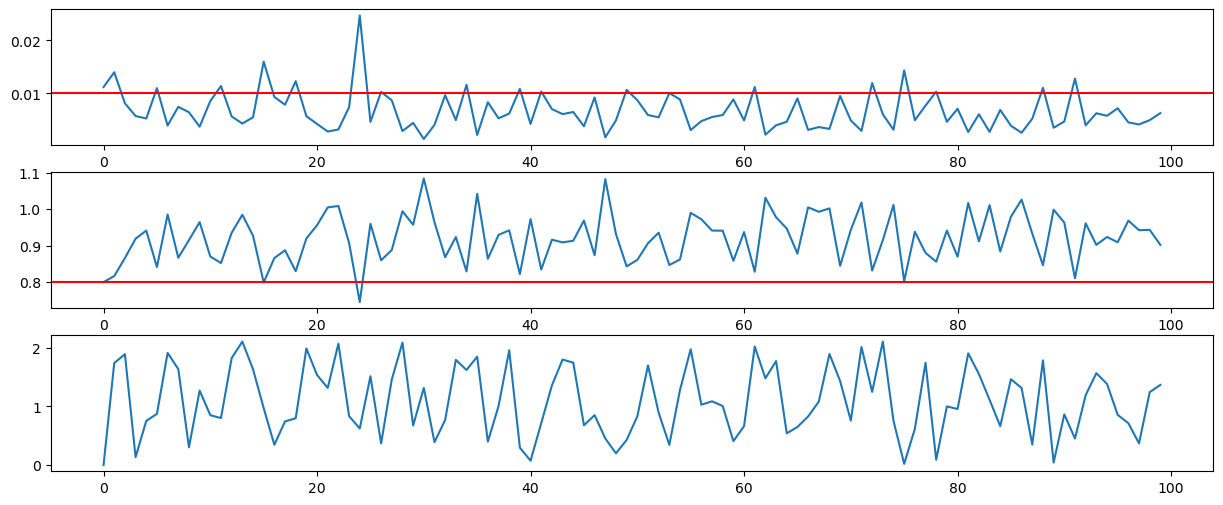

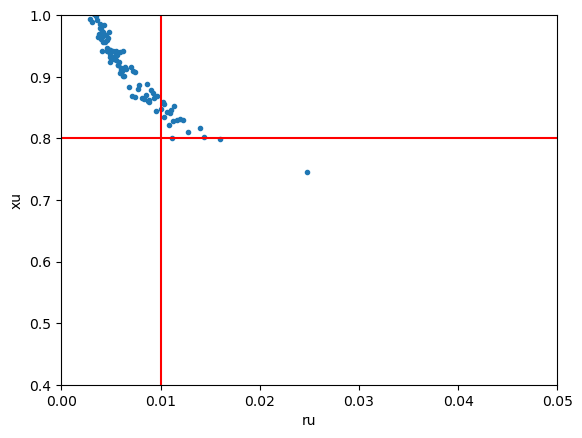

Text(0.5, 0, 'SNR')

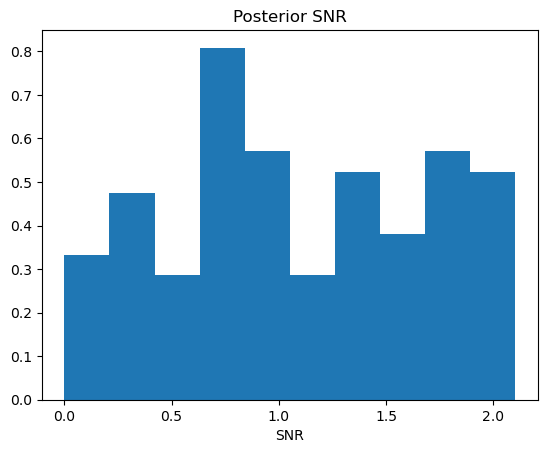

In [59]:
plt.figure(figsize=(15,6))
plt.subplot(3, 1, 1)
plt.plot(RU)
plt.axhline(ru_GT, c='r')
plt.subplot(3, 1, 2)
plt.plot(XU)
plt.axhline(xu_GT, c='r')
plt.subplot(3, 1, 3)
plt.plot(SNR)
plt.show()
plt.plot(RU, XU, '.')
plt.xlabel("ru")
plt.ylabel("xu")
plt.xlim((0, 5*ru_GT))
plt.axvline(ru_GT, c='r')
plt.axhline(xu_GT, c='r')
plt.ylim((0.4, 1))
plt.show()
plt.hist(SNR, density=True);
plt.title("Posterior SNR")
plt.xlabel("SNR")